In [144]:
import os
import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt
import json
import shutil
import itertools
import pandas as pd
from tqdm import tqdm

from typing import Dict, Tuple, Any

from Components.System import SimpleSquareExample 
from Components.Model import IrrigationSchedulingModel, IrrigationSchedulingCostQuadraticYield
from Components.Controllers import TimeVaryingCost_LQRc_RHG

In [145]:
# Reload scripts when executed
%load_ext autoreload
%autoreload 2

np.printoptions(linewidth=np.inf)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Create static model

In [146]:
parameter_file = "run_data/two_wells_analysis/finite_welfare/run_20251107-112119/two_wells_analysis_parameters_changed.json"
crop_repartition = np.array([[1., 1.], [0., 0.], [0., 0.], [0., 0.]])

In [147]:
# Initialize System and Model
model = IrrigationSchedulingModel(parameter_file, boundary_condition="Constant Head")

In [148]:
I_A_inv = np.linalg.inv(np.eye(model.A.shape[0]) - model.A)
B = sp.hstack(model.B_v)

# Well's radius influence for different commands

In [149]:
qs = [1, 10, 50, 100, 200, 500, 1000]
heads = []
for q in qs:
    u = - q * np.array([[1, 0, 0, 0, 0, 0, 0, 0]]).T
    heads.append(I_A_inv @ (B @ u + model.C))

In [62]:
well_ind = np.nonzero(model.well_to_cell[:,0])[0][0]
r,c = np.unravel_index(well_ind, shape=(model.n_row, model.n_col))

In [63]:
np.nonzero(model.well_to_cell[:,0])[0][0]

np.int32(312)

In [64]:
indices = np.indices((model.n_row, model.n_col)).transpose(1,2,0)
row = np.ravel_multi_index(indices[r,:].T, (model.n_row, model.n_col))

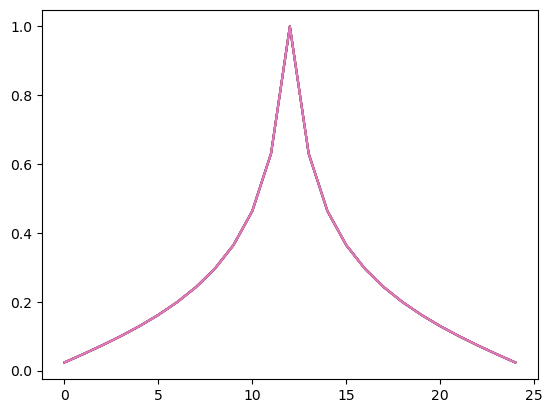

In [65]:
for i, q in enumerate(qs):
    plt.plot((10-heads[i][row])/(10 - heads[i][well_ind]))

Relative radius of influence is independent of $q$.

In [66]:
epsilon = (1 - 1/np.e)
epsilon

0.6321205588285577

In [67]:
relative_drawdown = (10-heads[i][row])/(10 - heads[i][well_ind])

In [68]:
x_R = np.searchsorted((1 - relative_drawdown[12:]).flatten(), epsilon)

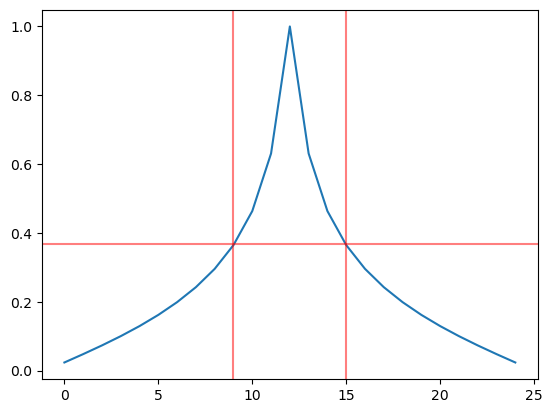

In [69]:
fig, ax = plt.subplots(1,1)
ax.plot(relative_drawdown)

ax.axhline(1 - epsilon, color='r', alpha=0.5)
ax.axvline(12 + x_R, color='r', alpha=0.5)
ax.axvline(12 - x_R, color='r', alpha=0.5)

plt.show()

# Check influence of aquifer depth

In [70]:
dir, file = os.path.split(parameter_file)
name, ext = file.split('.')
new_parameter_file = dir + '/' + name + '_tmp' + '.' + ext
shutil.copyfile(parameter_file, new_parameter_file)

'run_data/two_wells_analysis/finite_welfare/run_20251107-112119/two_wells_analysis_parameters_changed_tmp.json'

In [71]:
q = 10000
x_Rs = []
drawdowns = []
for depth in [50, 200, 500, 700, 1000]:
    with open(new_parameter_file, 'r+') as f:
        data = json.load(f)
        # modify field
        data['grid']['z_bot'] = -depth
        # overwrite file
        f.seek(0)
        json.dump(data, f, indent=4)
        f.truncate()
    
    # Initialize Model
    model = IrrigationSchedulingModel(new_parameter_file, boundary_condition="Constant Head")
    
    # Compute util matrices
    I_A_inv = np.linalg.inv(np.eye(model.A.shape[0]) - model.A)
    B = sp.hstack(model.B_v)
    
    # Generate equilibrium heads
    u = - q * np.array([[1, 0, 0, 0, 0, 0, 0, 0]]).T
    heads = I_A_inv @ (B @ u + model.C)
    
    # Get row relative drawdown
    drawdowns.append(10-heads[row])
    relative_drawdown = (10-heads[row])/(10 - heads[well_ind])
    
    # Compute influence radius
    x_Rs.append(np.searchsorted((1 - relative_drawdown[12:]).flatten(), epsilon))

In [72]:
x_Rs

[np.int64(3), np.int64(3), np.int64(3), np.int64(3), np.int64(3)]

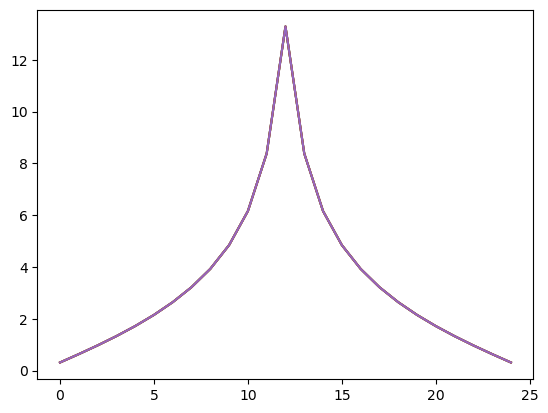

In [73]:
for drawdown in drawdowns:
    plt.plot(drawdown)

Influence radius seems to be independent of aquifer depth. --> Strange ?

Weight in front of $q$ depends on depth

--> Not in implem ?? --> specific storage is replaced by storativity ?

I think it make sense after all.  --> TODO check with modflow

In fact no: because we use specific storage in A and storativity in B

--> If B doesn't change, A should.

=> Problem in code!!

# Effect of conductivity

In [140]:
qs = [1, 10, 50, 100, 200, 500, 1000]
heads = []
for q in qs:
    u = - q * np.array([[1, 0, 0, 0, 0, 0, 0, 0]]).T
    heads.append(I_A_inv @ (B @ u + model.C))

In [75]:
indices = np.indices((model.n_row, model.n_col)).transpose(1,2,0)
cols = np.ravel_multi_index(indices[:, c].T, (model.n_row, model.n_col))

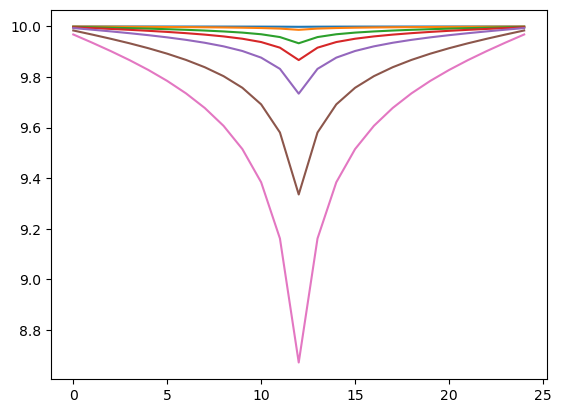

In [76]:
for i, q in enumerate(qs):
    plt.plot(heads[i][cols])

In [189]:
min_head_k1 = [heads[-1][12+12*25]]
q = 500
for distance in [40, 80, 120, 200, 280, 360, 400]:
    # Change Distance
    shutil.copyfile(parameter_file, new_parameter_file)
    with open(new_parameter_file, 'r+') as f:
        data = json.load(f)
        # modify field
        shift = (distance - 40) // 40
        wells = [[0, 490           ,     490],
                 [0, 530 + 40*shift,     490]]
        data['wells']['pos'] = wells
        # overwrite file
        f.seek(0)
        json.dump(data, f, indent=4)
        f.truncate()
    
    # Initialize Model
    model = IrrigationSchedulingModel(new_parameter_file, boundary_condition="Constant Head")
    
    # Compute util matrices
    I_A_inv = np.linalg.inv(np.eye(model.A.shape[0]) - model.A)
    B = sp.hstack(model.B_v)
    
    # Generate equilibrium heads
    u = - q * np.array([[1, 0, 0, 0, 1, 0, 0, 0]]).T
    heads_tmp = I_A_inv @ (B @ u + model.C)
    
    # Store minimum head
    min_head_k1.append(heads_tmp[12+25*12])

In [190]:
min_head_k1 = np.array(min_head_k1)
min_head_k1.T

array([[8.67151571, 8.91661375, 9.02777571, 9.0933894 , 9.17460461,
        9.22811874, 9.26913233, 9.28701045]])

In [193]:
min_head_k2 = []
q = 500
init = True
for distance in [40, 80, 120, 200, 280, 360, 400]:
    # Change Distance
    shutil.copyfile(parameter_file, new_parameter_file)
    with open(new_parameter_file, 'r+') as f:
        data = json.load(f)
        # modify field
        shift = (distance - 40) // 40
        wells = [[0, 490           ,     490],
                 [0, 530 + 40*shift,     490]]
        data['wells']['pos'] = wells
        data['physical']['hk'] = 0.1
        # overwrite file
        f.seek(0)
        json.dump(data, f, indent=4)
        f.truncate()
    
    # Initialize Model
    model = IrrigationSchedulingModel(new_parameter_file, boundary_condition="Constant Head")
    
    # Compute util matrices
    I_A_inv = np.linalg.inv(np.eye(model.A.shape[0]) - model.A)
    B = sp.hstack(model.B_v)
    
    
    # Generate equilibrium heads
    u = - q * np.array([[1, 0, 0, 0, 1, 0, 0, 0]]).T
    heads_tmp1 = I_A_inv @ (B @ u + model.C)
    # Only once, simulate two wells at the same position
    if init:
        u = - 2*q * np.array([[1, 0, 0, 0, 0, 0, 0, 0]]).T
        heads_tmp0 = I_A_inv @ (B @ u + model.C)
        min_head_k2.append(heads_tmp0[12+25*12])
        init = False
    
    # Store minimum head
    min_head_k2.append(heads_tmp1[12+25*12])

In [181]:
min_head_k2 = np.array(min_head_k2)
min_head_k2.T

array([[-3.28484288, -0.83386249,  0.27775705,  0.93389397,  1.74604608,
         2.28118741,  2.69132328,  2.87010451]])

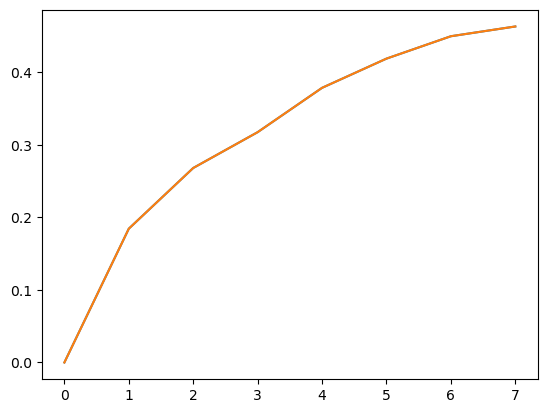

In [200]:
plt.plot((min_head_k1-min_head_k1[0])/abs(10-min_head_k1[0]))
plt.plot((min_head_k2-min_head_k2[0])/abs(10-min_head_k2[0]))

In [160]:
# Change Distance
shutil.copyfile(parameter_file, new_parameter_file)
with open(new_parameter_file, 'r+') as f:
    data = json.load(f)
    # modify field
    data['physical']['hk'] = 10
    # overwrite file
    f.seek(0)
    json.dump(data, f, indent=4)
    f.truncate()

# Initialize Model
model = IrrigationSchedulingModel(new_parameter_file, boundary_condition="Constant Head")

# Compute util matrices
I_A_inv = np.linalg.inv(np.eye(model.A.shape[0]) - model.A)
B = sp.hstack(model.B_v)

In [168]:
u = - 10 * np.array([[1, 0, 0, 0, 0, 0, 0, 0]]).T
heads_test = I_A_inv @ (B @ u + model.C)

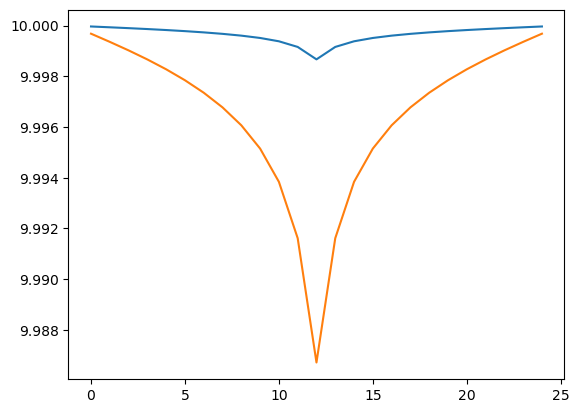

In [169]:
plt.plot(heads_test[cols])
plt.plot(heads[1][cols])

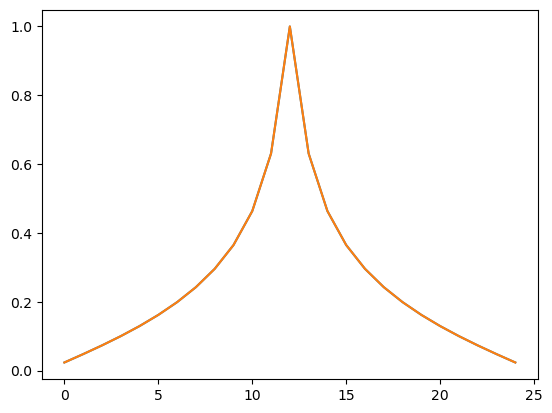

In [170]:
plt.plot((10-heads_test[cols])/(10-heads_test[12+25*12]))
plt.plot((10-heads[-1][cols])/(10-heads[-1][12+25*12]))

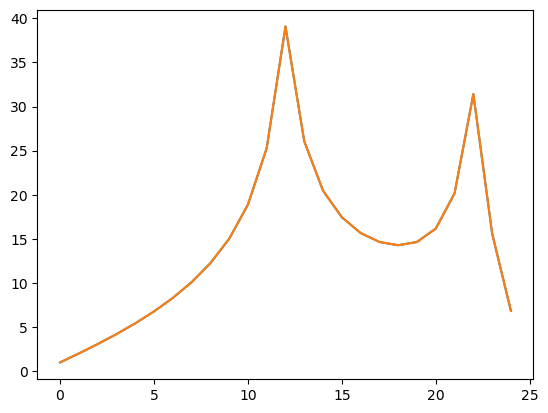

In [198]:
plt.plot((10-heads_tmp[cols])/min(10-heads_tmp[cols]))
plt.plot((10-heads_tmp1[cols])/min(10-heads_tmp1[cols]))